Proyek Klasifikasi Gambar: mikoajkolman/pokemon-images-first-generation17000-files

Nama: ASEP HARYANA SAPUTRA

Email: superaseph@gmail.com

ID Dicoding: mytheclipse

## 1. Persiapan Lingkungan

Mengimpor pustaka, mengatur seed, dan mengoptimalkan konfigurasi untuk performa maksimal. 
**Presisi standar (float32)** digunakan untuk komputasi agar efisien dalam penggunaan memori dan lebih cepat saat *training*.

Resolusi gambar diperkecil menjadi **224x224** agar sesuai dengan arsitektur EfficientNetV2B0 yang ringan namun tetap powerful.

In [14]:
!pip install -r requirements.txt 

In [15]:
import os
import shutil
import zipfile
import random
import io
import logging
import traceback
import time
import psutil
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
import splitfolders

from tensorflow.keras import layers, models, callbacks, regularizers, mixed_precision
from tensorflow.keras.applications import EfficientNetV2B0  # Diganti dengan V2B0 yang lebih ringan
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras import backend as K

class EMACheckpoint(callbacks.ModelCheckpoint):
    def __init__(self, filepath, **kwargs):
        super().__init__(filepath, **kwargs)

    def on_epoch_end(self, epoch, logs=None):
        try:
            old_weights = [tf.Variable(v) for v in self.model.trainable_variables]
            self.model.optimizer.finalize_variable_values(self.model.trainable_variables)
            super().on_epoch_end(epoch, logs)
        finally:
            for v, old_v in zip(self.model.trainable_variables, old_weights):
                v.assign(old_v)

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight

import ipywidgets as widgets
from IPython.display import display, clear_output

tf.keras.mixed_precision.set_global_policy('float32')

IMG_SIZE = (224, 224)  # Resolusi diturunkan agar lebih ringan dan cocok dengan EfficientNetV2B0
BATCH_SIZE = 16
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

os.environ["TF_DATA_AUTOTUNE_RAM_BUDGET"] = "8000000000"
os.environ['TF_XLA_FLAGS'] = '--tf_xla_enable_xla_devices=true'

AUTOTUNE = tf.data.AUTOTUNE

print(f"Setup selesai. IMG_SIZE={IMG_SIZE}, BATCH_SIZE={BATCH_SIZE}, Policy={tf.keras.mixed_precision.global_policy()}")

Setup selesai. IMG_SIZE=(224, 224), BATCH_SIZE=16, Policy=<DTypePolicy "float32">


## 2. Ekstraksi Dataset
(sama seperti asli)

In [16]:
zip_filename = 'pokemon.zip'
extract_dir = 'dataset_raw'

if os.path.exists(extract_dir) and len(os.listdir(extract_dir)) > 0:
    print(f"Folder {extract_dir} sudah ada dan tidak kosong. Ekstraksi dilewati.")
else:
    if os.path.exists(extract_dir):
        shutil.rmtree(extract_dir)
    os.makedirs(extract_dir, exist_ok=True)
    with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print("Ekstraksi selesai.")

Ekstraksi selesai.


## 3. Pembersihan Data (sama seperti asli)
(tetap sama, hanya pastikan semua gambar dalam format RGB)

In [17]:
base_dir = os.path.join(extract_dir, 'pokemon')
if not os.path.exists(base_dir):
    base_dir = extract_dir
print(f"Direktori utama: {base_dir}")

duplicate_map = {'Mr. Mime': 'MrMime'}
for src, dst in duplicate_map.items():
    src_path = os.path.join(base_dir, src)
    dst_path = os.path.join(base_dir, dst)
    if os.path.exists(src_path):
        if os.path.exists(dst_path):
            for f in os.listdir(src_path):
                shutil.move(os.path.join(src_path, f), os.path.join(dst_path, f))
            shutil.rmtree(src_path)
            print(f"Digabungkan {src} ke {dst}")
        else:
            os.rename(src_path, dst_path)
            print(f"Diganti nama {src} -> {dst}")

valid_ext = ('.jpg', '.jpeg', '.png', '.bmp')
removed = 0
for root, dirs, files in os.walk(base_dir):
    for file in files:
        fpath = os.path.join(root, file)
        ext = os.path.splitext(file)[1].lower()
        if ext not in valid_ext:
            os.remove(fpath)
            removed += 1
            continue
        try:
            with Image.open(fpath) as img:
                img.verify()
        except Exception:
            os.remove(fpath)
            removed += 1
print(f"File dihapus (ekstensi tidak valid/corrupt): {removed}")

for d in os.listdir(base_dir):
    dpath = os.path.join(base_dir, d)
    if os.path.isdir(dpath) and len(os.listdir(dpath)) == 0:
        shutil.rmtree(dpath)
        print(f"Folder kosong dihapus: {d}")

sanitized = 0
for root, dirs, files in os.walk(base_dir):
    for file in files:
        fpath = os.path.join(root, file)
        try:
            with Image.open(fpath) as img:
                if img.mode != 'RGB' or 'icc_profile' in img.info:
                    img = img.convert('RGB')
                    img.save(fpath, 'JPEG', quality=95, optimize=True)
                    sanitized += 1
        except Exception:
            pass
print(f"Gambar dinormalisasi: {sanitized}")

class_counts = {}
total_images = 0
for d in os.listdir(base_dir):
    dpath = os.path.join(base_dir, d)
    if os.path.isdir(dpath):
        cnt = len(os.listdir(dpath))
        class_counts[d] = cnt
        total_images += cnt
print(f"Total gambar valid: {total_images} dari {len(class_counts)} kelas")

Direktori utama: dataset_raw/pokemon
Digabungkan Mr. Mime ke MrMime
File dihapus (ekstensi tidak valid/corrupt): 778


/home/asephs/venvs/ml311/lib/python3.11/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Gambar dinormalisasi: 5019
Total gambar valid: 16485 dari 142 kelas


## 4. Pembagian Dataset (Train:Validation:Test = 70:15:15)

Proporsi diubah sedikit agar training lebih banyak.

In [18]:
output_dir = 'dataset_split'
if os.path.exists(output_dir):
    shutil.rmtree(output_dir)

splitfolders.ratio(
    base_dir,
    output=output_dir,
    seed=SEED,
    ratio=(0.7, 0.15, 0.15),
    group_prefix=None
)

train_dir = os.path.join(output_dir, 'train')
val_dir = os.path.join(output_dir, 'val')
test_dir = os.path.join(output_dir, 'test')

def count_images(path):
    return sum(len(files) for _, _, files in os.walk(path))

print(f"Train set: {count_images(train_dir)} gambar")
print(f"Validation set: {count_images(val_dir)} gambar")
print(f"Test set: {count_images(test_dir)} gambar")

Copying files: 16485 files [00:06, 2658.76 files/s]

Train set: 11475 gambar
Validation set: 2405 gambar
Test set: 2605 gambar


## 5. Persiapan Data Loader dengan Augmentasi Super Lengkap

Menggunakan `image_dataset_from_directory` dengan resolusi 224x224. 
Augmentasi mencakup: flip, rotasi, zoom, kontras, brightness, translation, shear, **CutMix**, **MixUp**, **RandomErasing**, dan GaussianNoise. 

In [19]:
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=None,
    label_mode='categorical',
    shuffle=True,
    seed=SEED
)
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

train_ds = train_ds.batch(BATCH_SIZE, drop_remainder=True)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    val_dir, image_size=IMG_SIZE, batch_size=None, label_mode='categorical', shuffle=False, seed=SEED
).batch(BATCH_SIZE, drop_remainder=True)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=None, label_mode='categorical', shuffle=False, seed=SEED
).batch(BATCH_SIZE, drop_remainder=True)

print(f"Jumlah kelas: {NUM_CLASSES}")
print(f"Contoh kelas: {class_names[:5]}...")

def sample_beta_distribution(size, concentration_0=0.2, concentration_1=0.2):
    gamma_1_sample = tf.random.gamma(shape=[size], alpha=concentration_1, dtype=tf.float32)
    gamma_2_sample = tf.random.gamma(shape=[size], alpha=concentration_0, dtype=tf.float32)
    return gamma_2_sample / (gamma_1_sample + gamma_2_sample)

def mix_up(images, labels, alpha=0.2):
    batch_size = tf.shape(images)[0]
    lambda_param = sample_beta_distribution(batch_size, alpha, alpha)
    lambda_param = tf.reshape(lambda_param, [batch_size, 1, 1, 1])
    random_indices = tf.random.shuffle(tf.range(batch_size))
    mixed_images = lambda_param * images + (1 - lambda_param) * tf.gather(images, random_indices)
    labels = tf.cast(labels, tf.float32)
    mixed_labels = lambda_param[...,0,0] * labels + (1 - lambda_param[...,0,0]) * tf.gather(labels, random_indices)
    return mixed_images, mixed_labels

def cut_mix(images, labels, alpha=0.2):
    batch_size = tf.shape(images)[0]
    lambda_param = sample_beta_distribution(batch_size, alpha, alpha)
    lambda_param = tf.reshape(lambda_param, [batch_size, 1, 1, 1])
    random_indices = tf.random.shuffle(tf.range(batch_size))
    
    image_height = tf.shape(images)[1]
    image_width = tf.shape(images)[2]
    cut_ratio = tf.math.sqrt(1.0 - lambda_param)
    cut_height = tf.cast(cut_ratio * tf.cast(image_height, tf.float32), tf.int32)
    cut_width = tf.cast(cut_ratio * tf.cast(image_width, tf.float32), tf.int32)
    
    cx = tf.random.uniform([batch_size, 1, 1, 1], 0, image_width, dtype=tf.int32)
    cy = tf.random.uniform([batch_size, 1, 1, 1], 0, image_height, dtype=tf.int32)
    
    x1 = tf.clip_by_value(cx - cut_width // 2, 0, image_width)
    y1 = tf.clip_by_value(cy - cut_height // 2, 0, image_height)
    x2 = tf.clip_by_value(cx + cut_width // 2, 0, image_width)
    y2 = tf.clip_by_value(cy + cut_height // 2, 0, image_height)
    
    y_range = tf.range(image_height, dtype=tf.int32)[None, :, None]
    x_range = tf.range(image_width, dtype=tf.int32)[None, None, :]
    
    y1_r = tf.squeeze(y1, axis=[1, 2, 3])
    y2_r = tf.squeeze(y2, axis=[1, 2, 3])
    x1_r = tf.squeeze(x1, axis=[1, 2, 3])
    x2_r = tf.squeeze(x2, axis=[1, 2, 3])
    
    y1_r = tf.reshape(y1_r, [-1, 1, 1])
    y2_r = tf.reshape(y2_r, [-1, 1, 1])
    x1_r = tf.reshape(x1_r, [-1, 1, 1])
    x2_r = tf.reshape(x2_r, [-1, 1, 1])
    
    mask_y = (y_range >= y1_r) & (y_range < y2_r)
    mask_x = (x_range >= x1_r) & (x_range < x2_r)
    
    mask_cut = mask_y & mask_x
    mask = ~mask_cut
    mask = mask[..., None]
    mask = tf.cast(mask, dtype=tf.bool)
    
    cutmix_images = tf.where(mask, images, tf.gather(images, random_indices))
    labels = tf.cast(labels, tf.float32)
    cutmix_labels = lambda_param[...,0,0] * labels + (1 - lambda_param[...,0,0]) * tf.gather(labels, random_indices)
    return cutmix_images, cutmix_labels

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.3),
    layers.RandomZoom(0.3),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2),
    layers.RandomTranslation(0.15, 0.15),
])

def random_erasing(images, labels, probability=0.5, area_ratio_range=(0.02, 0.4), aspect_ratio_range=(0.3, 3)):
    batch_size = tf.shape(images)[0]
    image_height = tf.shape(images)[1]
    image_width = tf.shape(images)[2]
    
    def erasing_single(img):
        if tf.random.uniform([]) < probability:
            area = tf.cast(image_height * image_width, tf.float32)
            target_area = tf.random.uniform([], area_ratio_range[0], area_ratio_range[1], dtype=tf.float32) * area
            aspect_ratio = tf.random.uniform([], aspect_ratio_range[0], aspect_ratio_range[1], dtype=tf.float32)
            h = tf.cast(tf.math.sqrt(target_area * aspect_ratio), tf.int32)
            w = tf.cast(tf.math.sqrt(target_area / aspect_ratio), tf.int32)
            h = tf.minimum(h, image_height - 1)
            w = tf.minimum(w, image_width - 1)
            x = tf.random.uniform([], 0, image_width - w, dtype=tf.int32)
            y = tf.random.uniform([], 0, image_height - h, dtype=tf.int32)
            
            random_values = tf.random.uniform(tf.shape(img), 0.0, 255.0, dtype=tf.float32)
            
            y_range = tf.range(image_height, dtype=tf.int32)[:, None]
            x_range = tf.range(image_width, dtype=tf.int32)[None, :]
            
            mask_y = (y_range >= y) & (y_range < y + h)
            mask_x = (x_range >= x) & (x_range < x + w)
            
            mask_cut = mask_y & mask_x
            mask_cut = mask_cut[..., None]
            mask_cut = tf.cast(mask_cut, dtype=tf.float32)
            
            erased_img = img * (1 - mask_cut) + random_values * mask_cut
            return erased_img
        else:
            return img
    
    images = tf.map_fn(erasing_single, images, dtype=tf.float32)
    return images, labels

def preprocess(images, labels):
    return preprocess_input(images), labels

def augment_and_preprocess(images, labels):
    images = tf.image.resize(images, IMG_SIZE)
    images = tf.cast(images, tf.float32)
    x = data_augmentation(images, training=True)
    x, labels = random_erasing(x, labels, probability=0.3)
    x = tf.clip_by_value(x, 0.0, 255.0)
    return preprocess_input(x), labels

train_generator = train_ds.map(augment_and_preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
validation_generator = val_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_generator = test_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)


Found 11475 files belonging to 142 classes.
Found 2405 files belonging to 142 classes.
Found 2605 files belonging to 142 classes.
Jumlah kelas: 142
Contoh kelas: ['Abra', 'Aerodactyl', 'Alakazam', 'Arbok', 'Arcanine']...


## 6. Visualisasi Sampel Data (dengan Augmentasi)
(sama seperti asli)

2026-02-17 17:02:17.144508: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: CANCELLED: Loop execution was cancelled.
	 [[{{node map/while/LoopCond/_16}}]]


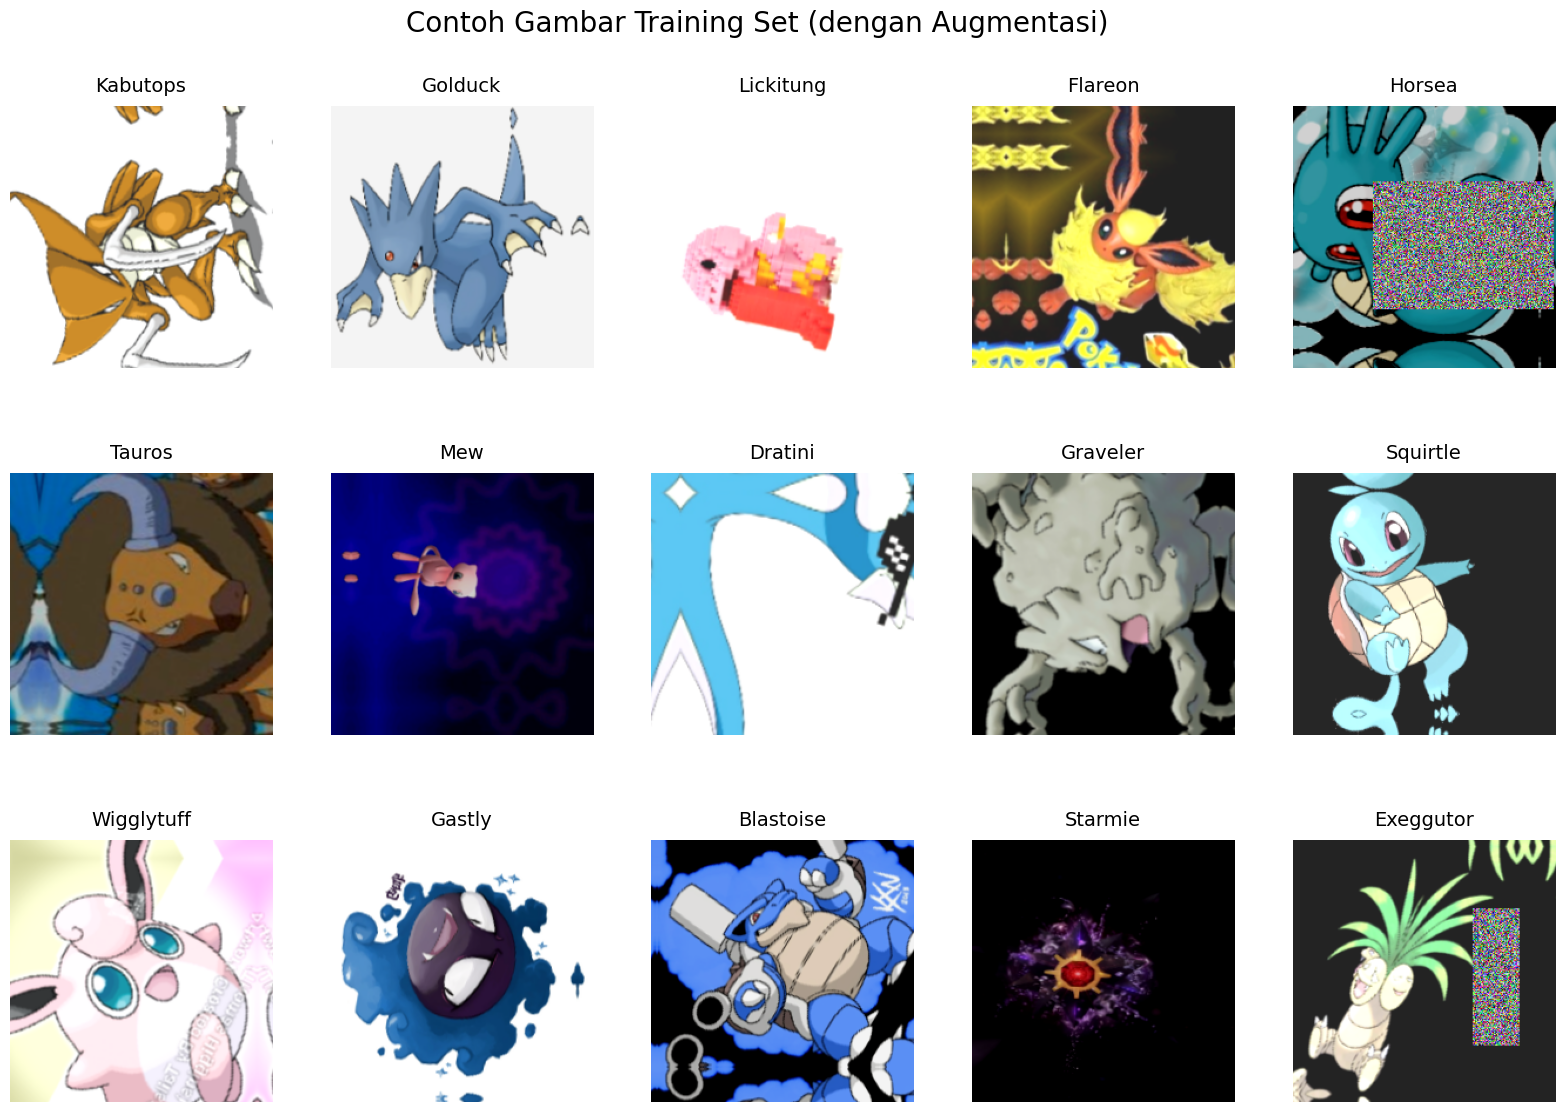

In [20]:
batch_data = next(iter(train_generator))
if len(batch_data) == 3:
    sample_images, sample_labels, _ = batch_data
else:
    sample_images, sample_labels = batch_data

plt.figure(figsize=(20, 12))
for i in range(15):
    plt.subplot(3, 5, i+1)
    
    img_raw = sample_images[i].numpy()
    img_np = np.clip(img_raw, 0, 255).astype("uint8")
    
    plt.imshow(img_np)
    label_idx = np.argmax(sample_labels[i])
    plt.title(class_names[label_idx], fontsize=14, pad=10)
    plt.axis('off')

plt.suptitle('Contoh Gambar Training Set (dengan Augmentasi)', fontsize=20, y=0.96)
plt.subplots_adjust(top=0.88, bottom=0.05, hspace=0.4, wspace=0.2)
plt.show()

## 7. Penanganan Ketidakseimbangan Kelas dengan Sample Weight (Diperhalus)

Menggunakan `compute_class_weight` dari sklearn untuk menghitung bobot yang lebih akurat, lalu dibatasi maksimum 2.5.

In [21]:
train_class_counts = Counter()
for class_name in class_names:
    folder = os.path.join(train_dir, class_name)
    if os.path.exists(folder):
        train_class_counts[class_name] = len(os.listdir(folder))

y_train_integer = []
for i, cls in enumerate(class_names):
    y_train_integer.extend([i] * train_class_counts[cls])

class_weights_array = compute_class_weight('balanced', classes=np.unique(y_train_integer), y=y_train_integer)
class_weights_list = [min(w, 2.5) for w in class_weights_array]

class_weights_tensor = tf.constant(class_weights_list, dtype=tf.float32)

def add_sample_weight(image, label):
    class_indices = tf.argmax(label, axis=-1)
    sample_weights = tf.gather(class_weights_tensor, class_indices)
    return image, label, sample_weights

train_generator = train_generator.map(add_sample_weight, num_parallel_calls=AUTOTUNE)

print("Bobot kelas (dibatasi max 2.5):")
for i, name in enumerate(class_names[:10]):
    print(f"{name}: {class_weights_list[i]:.4f}")
print("...")

Bobot kelas (dibatasi max 2.5):
Abra: 1.9240
Aerodactyl: 1.3697
Alakazam: 1.3697
Arbok: 0.8979
Arcanine: 1.4430
Articuno: 1.2432
Beedrill: 1.3468
Bellsprout: 0.8880
Blastoise: 0.8081
Bulbasaur: 0.7846
...


## 8. Membangun Model CNN dengan Transfer Learning (EfficientNetV2B0)

Menggunakan **EfficientNetV2B0** sebagai base model yang ringan (sekitar 7 juta parameter) namun tetap powerful. Ditambah layer konvolusi tambahan, batch normalization, dropout tinggi, dan L2 regularization. Model dikompilasi dengan AdamW dan label smoothing 0.2.

In [22]:
def create_model():
    base_model = EfficientNetV2B0(  # Diganti dengan V2B0 yang ringan
        input_shape=IMG_SIZE + (3,),
        include_top=False,
        weights='imagenet',
        include_preprocessing=True
    )
    base_model.trainable = False

    model = models.Sequential([
        layers.Input(shape=IMG_SIZE + (3,)),
        base_model,
        
        layers.Conv2D(512, (3, 3), padding='same', activation='swish'),
                      
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.2),
        
        layers.Conv2D(256, (3, 3), padding='same', activation='swish'),
                      
        layers.BatchNormalization(),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        
        layers.Dense(1024, activation='swish'),
                     
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        
        layers.Dense(NUM_CLASSES, activation='softmax', dtype='float32')
    ])
    return model

checkpoint_path = 'submission/best_model.keras'
if os.path.exists(checkpoint_path):
    try:
        model = models.load_model(checkpoint_path)
    except:
        model = create_model()
else:
    model = create_model()

model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 512)      │     5,898,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 7, 7, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 3, 3, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 3, 3, 256)      │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 3, 3, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 142)            │       145,550 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,413,854 (51.17 MB)

 Trainable params: 7,490,958 (28.58 MB)

 Non-trainable params: 5,922,896 (22.59 MB)

## 9. Callbacks

Menggunakan ModelCheckpoint, EarlyStopping (patience 30), ReduceLROnPlateau (mode min, faktor 0.2), CSVLogger, TensorBoard, dan **ExponentialMovingAverage** dari tensorflow-addons.

In [23]:
log_dir = "logs/fit/" + time.strftime("%Y%m%d-%H%M%S")
os.makedirs("submission", exist_ok=True)

checkpoint = callbacks.ModelCheckpoint(
    'submission/best_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

early_stop = callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=30,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=5,
    min_lr=1e-8,
    verbose=1
)

csv_logger = callbacks.CSVLogger('submission/training_log.csv')
tensorboard = callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1, write_graph=True)

ema_callback = EMACheckpoint(
    filepath='submission/best_model_ema.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

callbacks_list = [checkpoint, early_stop, reduce_lr, csv_logger, tensorboard, ema_callback]

## 10. Pelatihan Model (Fase 1: Head Saja)

Menggunakan optimizer AdamW dengan learning rate 1e-3 dan weight decay 1e-4, loss categorical crossentropy dengan label smoothing 0.2.

In [24]:
model.compile(
    optimizer=AdamW(use_ema=True, ema_momentum=0.999, learning_rate=1e-3, weight_decay=1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.2),
    metrics=['accuracy']
)

history1 = model.fit(
    train_generator,
    epochs=50,
    validation_data=validation_generator,
    callbacks=callbacks_list
)

Epoch 1/50
717/717 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.0938 - loss: 5.2063
Epoch 1: val_accuracy improved from None to 0.49958, saving model to submission/best_model.keras

Epoch 1: finished saving model to submission/best_model.keras

Epoch 1: val_accuracy improved from None to 0.49958, saving model to submission/best_model_ema.keras

Epoch 1: finished saving model to submission/best_model_ema.keras
717/717 ━━━━━━━━━━━━━━━━━━━━ 48s 48ms/step - accuracy: 0.1605 - loss: 4.6785 - val_accuracy: 0.4996 - val_loss: 3.6044 - learning_rate: 0.0010
Epoch 2/50
716/717 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.3238 - loss: 3.7909
Epoch 2: val_accuracy improved from 0.49958 to 0.66167, saving model to submission/best_model.keras

Epoch 2: finished saving model to submission/best_model.keras

Epoch 2: val_accuracy improved from 0.49958 to 0.66167, saving model to submission/best_model_ema.keras

Epoch 2: finished saving model to submission/best_model_ema.keras
717/717 ━━━━━━━━━━━

## 11. Fine-Tuning Bertahap (Fase 2, 3, ...)

Kita akan melakukan fine-tuning dengan membuka layer base model secara bertahap, dimulai dari layer atas, kemudian seluruh layer. Setiap fase menggunakan learning rate yang lebih kecil dan durasi lebih panjang.

In [26]:
base_model = model.layers[0]
base_model.trainable = True
for layer in base_model.layers[:-100]:
    layer.trainable = False

model.compile(
    optimizer=AdamW(use_ema=True, ema_momentum=0.999, learning_rate=1e-4, weight_decay=1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.2),
    metrics=['accuracy']
)

history2 = model.fit(
    train_generator,
    epochs=100,
    initial_epoch=history1.epoch[-1] + 1,
    validation_data=validation_generator,
    callbacks=callbacks_list
)

base_model.trainable = True

model.compile(
    optimizer=AdamW(use_ema=True, ema_momentum=0.999, learning_rate=5e-5, weight_decay=1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.2),
    metrics=['accuracy']
)

history3 = model.fit(
    train_generator,
    epochs=150,
    initial_epoch=history2.epoch[-1] + 1,
    validation_data=validation_generator,
    callbacks=callbacks_list
)

Epoch 51/100
717/717 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9395 - loss: 1.7993
Epoch 51: val_accuracy did not improve from 0.94750

Epoch 51: val_accuracy did not improve from 0.94750
717/717 ━━━━━━━━━━━━━━━━━━━━ 65s 58ms/step - accuracy: 0.9392 - loss: 1.8024 - val_accuracy: 0.9463 - val_loss: 1.7950 - learning_rate: 1.0000e-04
Epoch 52/100
716/717 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9374 - loss: 1.8100
Epoch 52: val_accuracy did not improve from 0.94750

Epoch 52: val_accuracy did not improve from 0.94750
717/717 ━━━━━━━━━━━━━━━━━━━━ 39s 54ms/step - accuracy: 0.9378 - loss: 1.8041 - val_accuracy: 0.9454 - val_loss: 1.7828 - learning_rate: 1.0000e-04
Epoch 53/100
716/717 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9370 - loss: 1.8067
Epoch 53: val_accuracy improved from 0.94750 to 0.94917, saving model to submission/best_model.keras

Epoch 53: finished saving model to submission/best_model.keras

Epoch 53: val_accuracy improved from 0.94750 to 0.94917, saving

2026-02-17 18:07:58.384142: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 9642880 bytes after encountering the first element of size 9642880 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


717/717 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.9528 - loss: 1.7592
Epoch 64: val_accuracy did not improve from 0.95250

Epoch 64: val_accuracy did not improve from 0.95250
717/717 ━━━━━━━━━━━━━━━━━━━━ 40s 56ms/step - accuracy: 0.9506 - loss: 1.7612 - val_accuracy: 0.9463 - val_loss: 1.7696 - learning_rate: 1.0000e-04
Epoch 65/100
  2/717 ━━━━━━━━━━━━━━━━━━━━ 1:09 97ms/step - accuracy: 0.9062 - loss: 2.1070 

2026-02-17 18:08:38.644417: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 9642880 bytes after encountering the first element of size 9642880 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


716/717 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.9488 - loss: 1.7695
Epoch 65: val_accuracy did not improve from 0.95250

Epoch 65: ReduceLROnPlateau reducing learning rate to 1.9999999494757503e-05.

Epoch 65: val_accuracy did not improve from 0.95250
717/717 ━━━━━━━━━━━━━━━━━━━━ 40s 56ms/step - accuracy: 0.9503 - loss: 1.7585 - val_accuracy: 0.9467 - val_loss: 1.7674 - learning_rate: 1.0000e-04
Epoch 66/100
716/717 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9558 - loss: 1.7519
Epoch 66: val_accuracy did not improve from 0.95250

Epoch 66: val_accuracy did not improve from 0.95250
717/717 ━━━━━━━━━━━━━━━━━━━━ 40s 55ms/step - accuracy: 0.9549 - loss: 1.7501 - val_accuracy: 0.9500 - val_loss: 1.7542 - learning_rate: 2.0000e-05
Epoch 67/100
716/717 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9508 - loss: 1.7606
Epoch 67: val_accuracy did not improve from 0.95250

Epoch 67: val_accuracy did not improve from 0.95250
717/717 ━━━━━━━━━━━━━━━━━━━━ 39s 54ms/step - accuracy: 0.9

2026-02-17 18:11:54.883757: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 9642880 bytes after encountering the first element of size 9642880 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


... (15 outputs left out)

2026-02-17 18:46:02.351570: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 9642880 bytes after encountering the first element of size 9642880 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


717/717 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9649 - loss: 1.7204
Epoch 120: val_accuracy did not improve from 0.95458

Epoch 120: val_accuracy did not improve from 0.95458
717/717 ━━━━━━━━━━━━━━━━━━━━ 40s 55ms/step - accuracy: 0.9636 - loss: 1.7208 - val_accuracy: 0.9513 - val_loss: 1.7440 - learning_rate: 4.0000e-07
Epoch 121/150
716/717 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.9612 - loss: 1.7161
Epoch 121: val_accuracy did not improve from 0.95458

Epoch 121: val_accuracy did not improve from 0.95458
717/717 ━━━━━━━━━━━━━━━━━━━━ 41s 57ms/step - accuracy: 0.9613 - loss: 1.7149 - val_accuracy: 0.9513 - val_loss: 1.7466 - learning_rate: 4.0000e-07
Epoch 122/150
716/717 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9627 - loss: 1.7173
Epoch 122: val_accuracy did not improve from 0.95458

Epoch 122: val_accuracy did not improve from 0.95458
717/717 ━━━━━━━━━━━━━━━━━━━━ 40s 55ms/step - accuracy: 0.9610 - loss: 1.7212 - val_accuracy: 0.9513 - val_loss: 1.7485 - learning

2026-02-17 18:48:03.036581: W tensorflow/core/kernels/data/prefetch_autotuner.cc:52] Prefetch autotuner tried to allocate 9642880 bytes after encountering the first element of size 9642880 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


717/717 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9611 - loss: 1.7220
Epoch 123: val_accuracy did not improve from 0.95458

Epoch 123: val_accuracy did not improve from 0.95458
717/717 ━━━━━━━━━━━━━━━━━━━━ 40s 55ms/step - accuracy: 0.9616 - loss: 1.7189 - val_accuracy: 0.9542 - val_loss: 1.7471 - learning_rate: 4.0000e-07
Epoch 124/150
716/717 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9617 - loss: 1.7271
Epoch 124: val_accuracy did not improve from 0.95458

Epoch 124: val_accuracy did not improve from 0.95458
717/717 ━━━━━━━━━━━━━━━━━━━━ 39s 54ms/step - accuracy: 0.9604 - loss: 1.7215 - val_accuracy: 0.9521 - val_loss: 1.7418 - learning_rate: 4.0000e-07
Epoch 125/150
717/717 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.9585 - loss: 1.7237
Epoch 125: val_accuracy did not improve from 0.95458

Epoch 125: val_accuracy did not improve from 0.95458
717/717 ━━━━━━━━━━━━━━━━━━━━ 40s 55ms/step - accuracy: 0.9603 - loss: 1.7190 - val_accuracy: 0.9521 - val_loss: 1.7453 - learning

## 12. Plot Akurasi dan Loss (Gabungan Semua Fase)
(sama seperti asli, tetapi menggabungkan semua history)

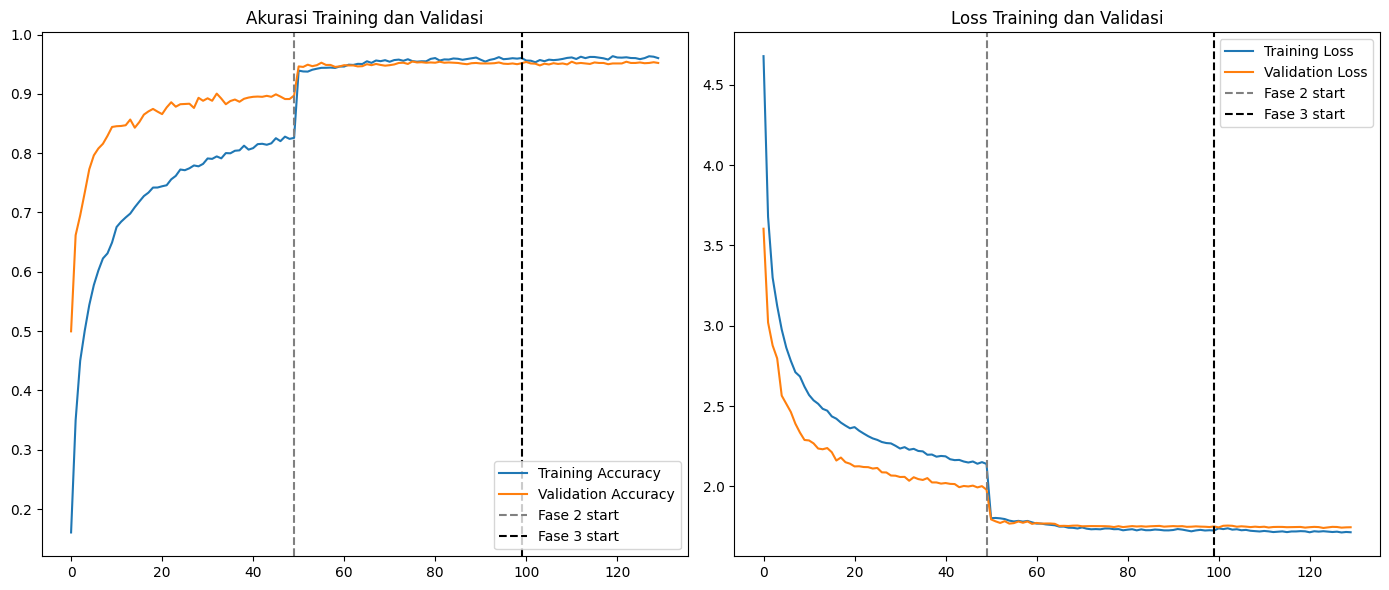

In [27]:
acc = history1.history['accuracy'] + history2.history['accuracy'] + history3.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy'] + history3.history['val_accuracy']
loss = history1.history['loss'] + history2.history['loss'] + history3.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss'] + history3.history['val_loss']

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.axvline(x=len(history1.history['accuracy'])-1, color='gray', linestyle='--', label='Fase 2 start')
plt.axvline(x=len(history1.history['accuracy'])+len(history2.history['accuracy'])-1, color='black', linestyle='--', label='Fase 3 start')
plt.legend()
plt.title('Akurasi Training dan Validasi')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.axvline(x=len(history1.history['loss'])-1, color='gray', linestyle='--', label='Fase 2 start')
plt.axvline(x=len(history1.history['loss'])+len(history2.history['loss'])-1, color='black', linestyle='--', label='Fase 3 start')
plt.legend()
plt.title('Loss Training dan Validasi')
plt.tight_layout()
plt.show()

## 13. Evaluasi pada Test Set dengan Test Time Augmentation (TTA)

Menggunakan model terbaik (EMA) dan menerapkan TTA untuk meningkatkan akurasi.

In [28]:
best_model = tf.keras.models.load_model('submission/best_model_ema.keras')

def tta_predict(model, image_batch, n_aug=5):
    predictions = []
    for _ in range(n_aug):
        aug = tf.keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.1),
            layers.RandomZoom(0.1),
        ])
        aug_images = aug(image_batch, training=True)
        preds = model.predict(aug_images, verbose=0)
        predictions.append(preds)
    return np.mean(predictions, axis=0)

y_true = []
y_pred = []
for images, labels in test_generator:
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    tta_probs = tta_predict(best_model, images, n_aug=5)
    y_pred.extend(np.argmax(tta_probs, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

test_accuracy = np.mean(y_true == y_pred)
print(f"\nTest Accuracy dengan TTA: {test_accuracy:.4f}")

if test_accuracy >= 0.95:
    print("✅ Model memenuhi target akurasi >=95%.")
else:
    print("⚠️  Model belum mencapai 95%.")


Test Accuracy dengan TTA: 0.9614
✅ Model memenuhi target akurasi >=95%.


## 14. Confusion Matrix dan Classification Report
(sama seperti asli)


Classification Report:
              precision    recall  f1-score   support

        Abra       0.88      0.78      0.82         9
  Aerodactyl       0.93      0.93      0.93        14
    Alakazam       0.79      0.79      0.79        14
       Arbok       1.00      0.95      0.97        20
    Arcanine       1.00      1.00      1.00        13
    Articuno       1.00      1.00      1.00        15
    Beedrill       1.00      1.00      1.00        14
  Bellsprout       0.95      1.00      0.98        20
   Blastoise       0.96      1.00      0.98        22
   Bulbasaur       1.00      1.00      1.00        23
  Butterfree       1.00      1.00      1.00        19
    Caterpie       1.00      1.00      1.00        20
     Chansey       1.00      1.00      1.00        17
   Charizard       1.00      0.94      0.97        16
  Charmander       1.00      1.00      1.00        20
  Charmeleon       1.00      1.00      1.00        23
    Clefable       0.94      1.00      0.97        16
   

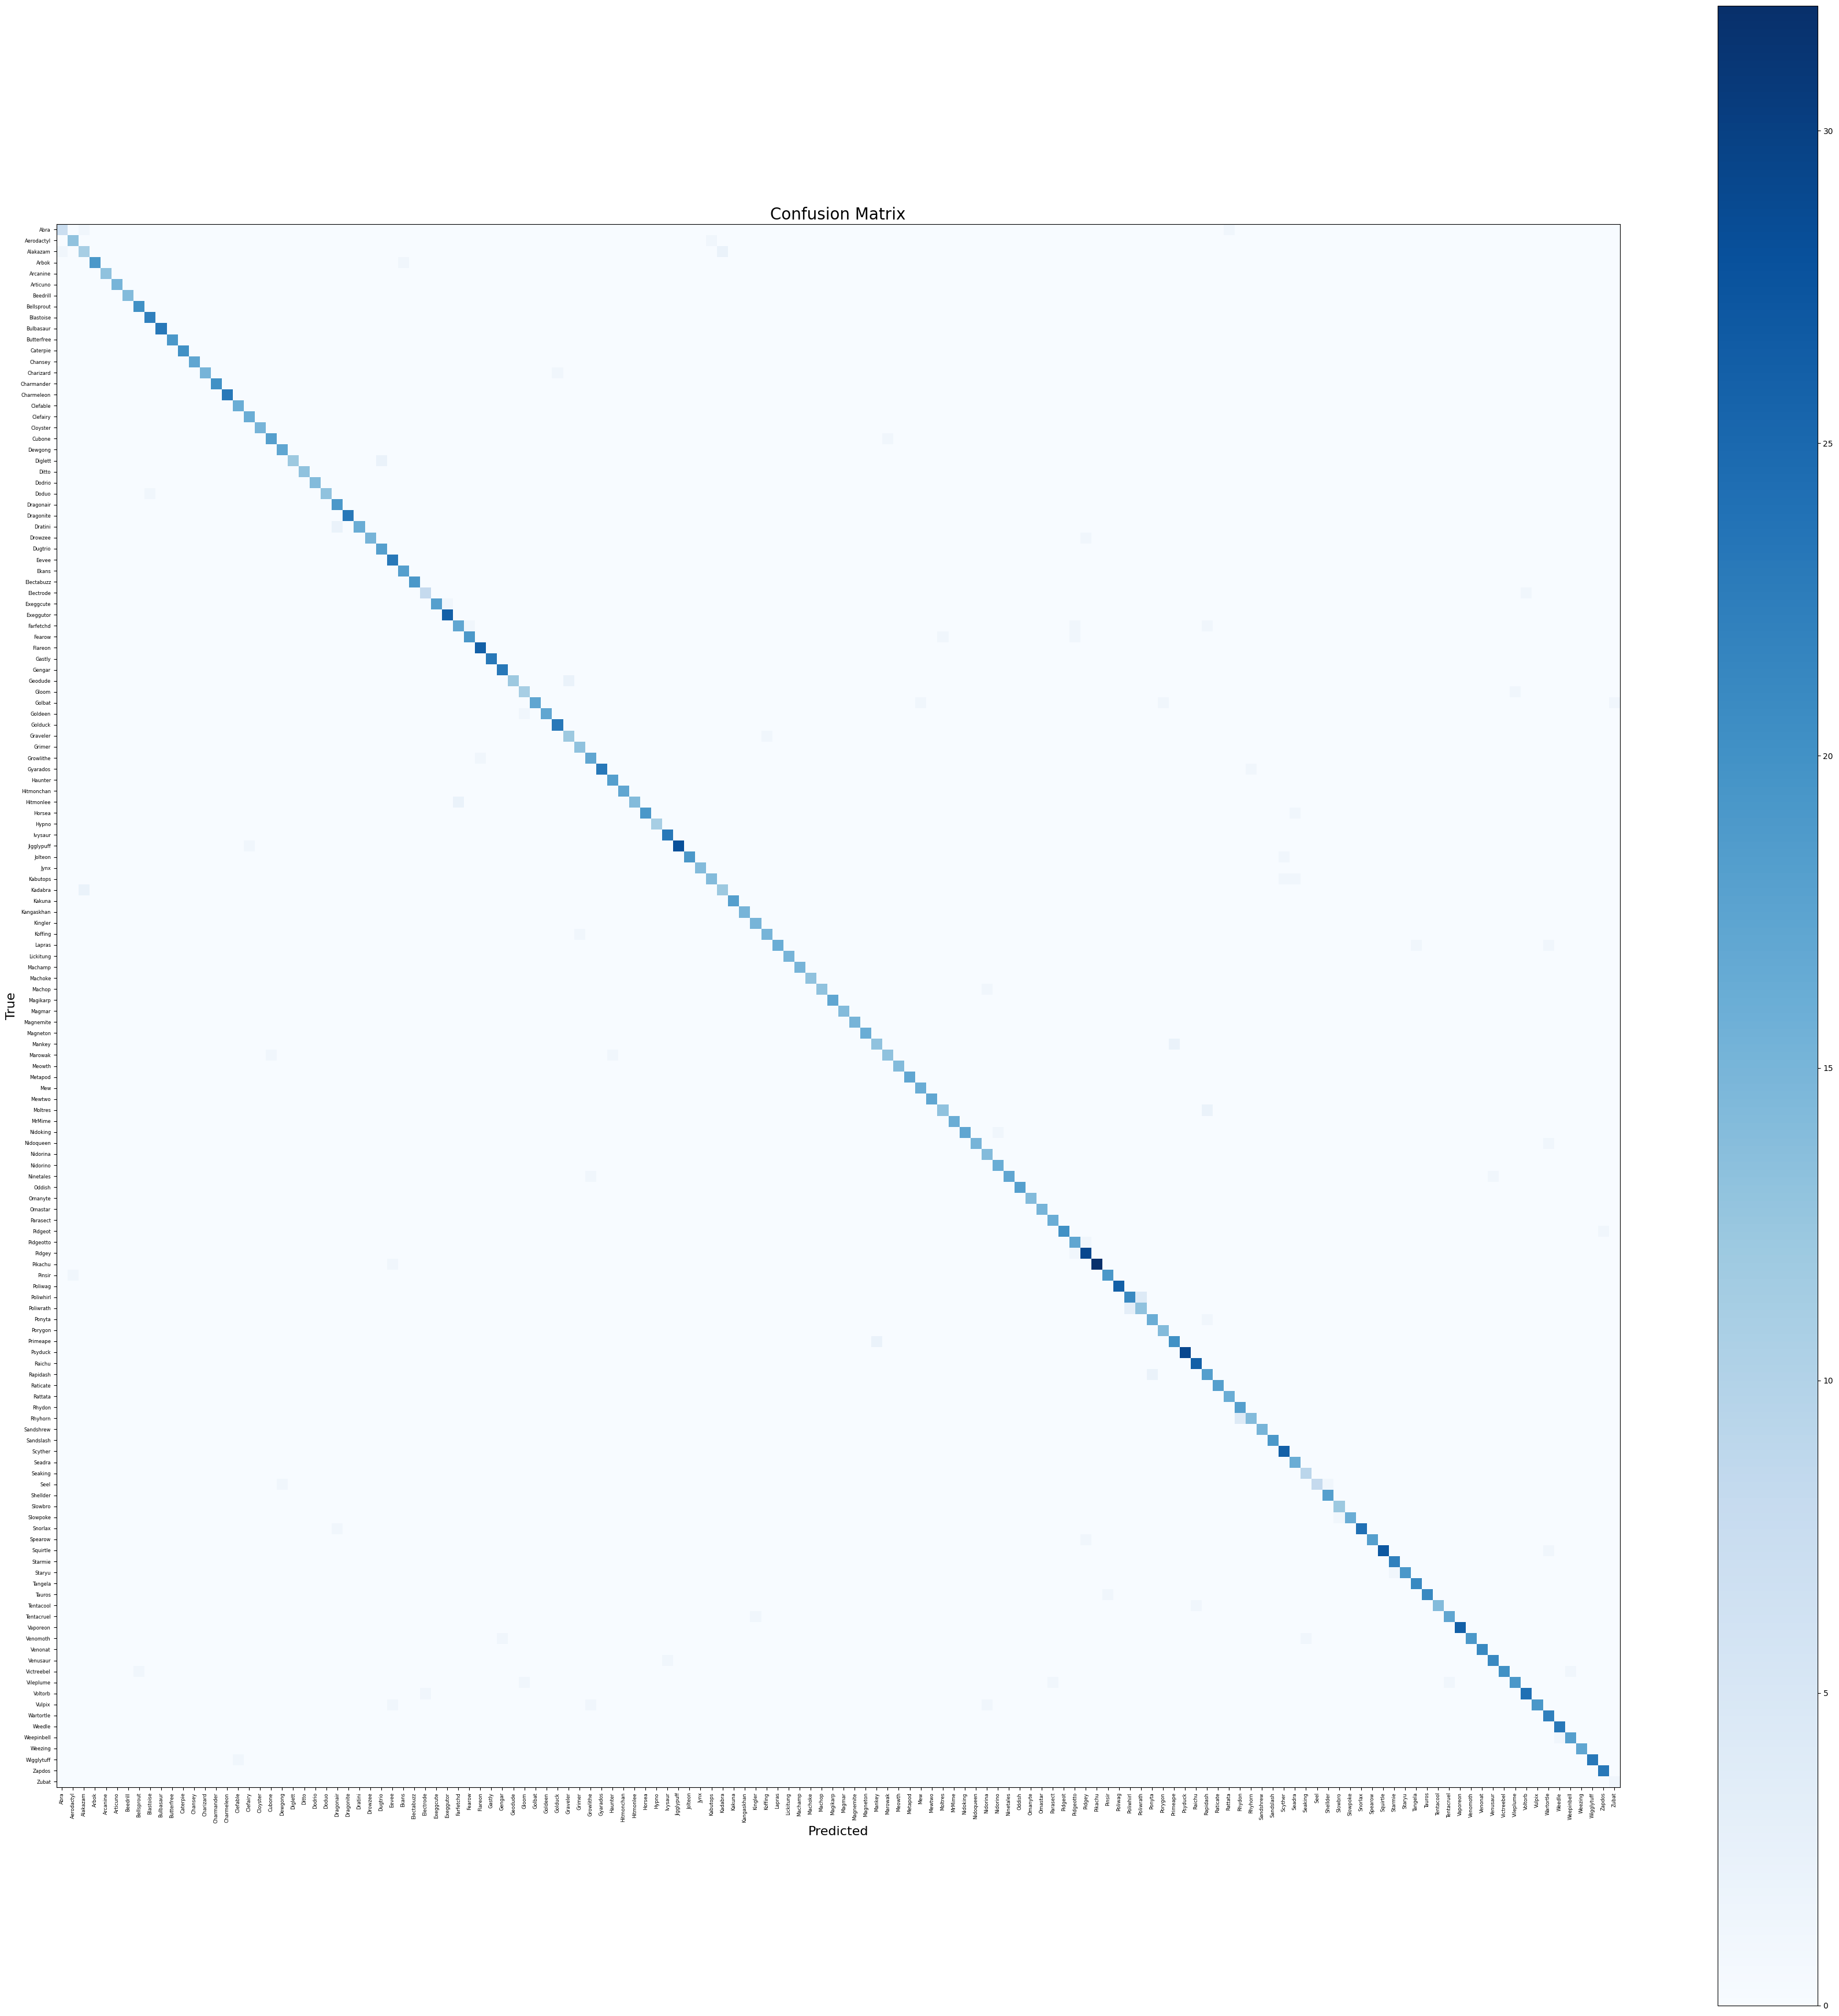

In [29]:
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(35, 35))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix', fontsize=20)
plt.colorbar()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names, rotation=90, fontsize=6)
plt.yticks(tick_marks, class_names, fontsize=6)
plt.xlabel('Predicted', fontsize=16)
plt.ylabel('True', fontsize=16)
plt.tight_layout()
plt.show()

## 15. Simpan Model dalam Berbagai Format (SavedModel, TF-Lite, TFJS)

Menyimpan model dalam format SavedModel, TF-Lite (dengan kuantisasi float16 dan int8), dan TFJS. Untuk TF-Lite, kita konversi dengan optimasi ukuran dan kecepatan.

In [31]:
%run export_model.py

2026-02-17 19:06:58,001 [INFO] === EXPORT STARTED ===
2026-02-17 19:06:58,001 [INFO] Loading model...
2026-02-17 19:06:59,019 [INFO] Model loaded successfully
2026-02-17 19:06:59,019 [INFO] Exporting SavedModel...


INFO:tensorflow:Assets written to: /home/asephs/Pijak/Proyek_Klasifikasi_Gambar/submission/saved_model/assets


2026-02-17 19:07:07,879 [INFO] Assets written to: /home/asephs/Pijak/Proyek_Klasifikasi_Gambar/submission/saved_model/assets
2026-02-17 19:07:07,971 [INFO] SavedModel OK
2026-02-17 19:07:07,972 [INFO] Converting to TFLite...


INFO:tensorflow:Assets written to: /tmp/tmp12vh1hd9/assets


2026-02-17 19:07:13,283 [INFO] Assets written to: /tmp/tmp12vh1hd9/assets


Saved artifact at '/tmp/tmp12vh1hd9'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_5')
Output Type:
  TensorSpec(shape=(None, 142), dtype=tf.float32, name=None)
Captures:
  140054900364624: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  140054900364432: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  140054900362896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140054900364048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140054900363664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140054900365392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140054900365968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140054900363856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140054900362512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140054900365776: TensorSpec(shape=(), dtype=tf.resource, name=N

W0000 00:00:1771330034.839696  165178 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1771330034.839736  165178 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
2026-02-17 19:07:14.842731: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /tmp/tmp12vh1hd9
2026-02-17 19:07:14.858253: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-02-17 19:07:14.858270: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp12vh1hd9
I0000 00:00:1771330034.986544  165178 mlir_graph_optimization_pass.cc:425] MLIR V1 optimization pass is not enabled
2026-02-17 19:07:15.007519: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-02-17 19:07:15.848562: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp12vh1hd9
2026-02-17 19:07:16.017683: I tensorflow/cc/saved_model/loader.cc:471] SavedModel 

## 16. Inference dengan Model TF-Lite

Found 2605 files belonging to 142 classes.


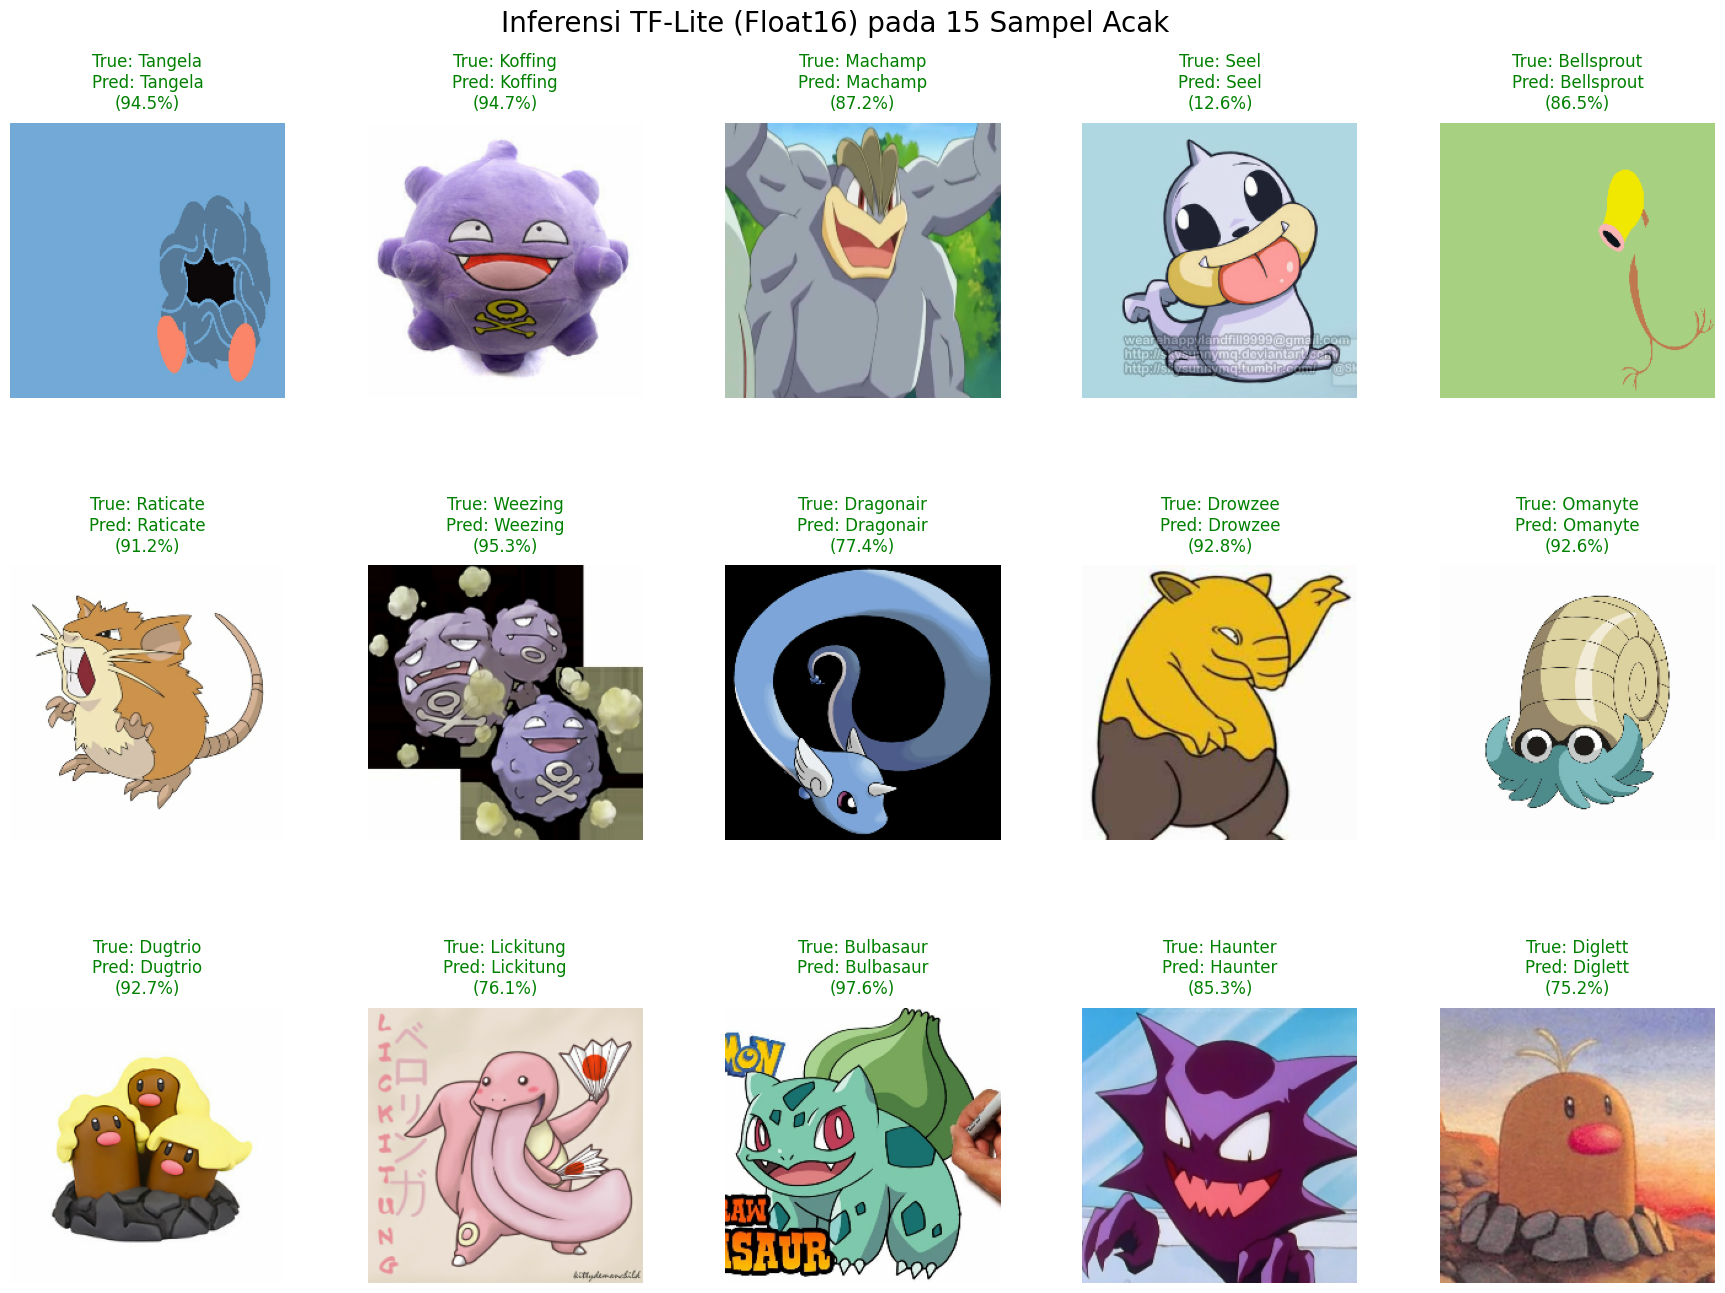

In [34]:
interpreter = tf.lite.Interpreter(model_path='submission/tflite/model.tflite')
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

input_index = input_details[0]['index']
input_dtype = input_details[0]['dtype']

output_index = output_details[0]['index']

viz_ds = tf.keras.preprocessing.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=32,
    label_mode='categorical',
    shuffle=True,
    seed=random.randint(0, 1000)
)

images, labels = next(iter(viz_ds.map(preprocess)))

plt.figure(figsize=(22, 14))

for i in range(15):
    img = images[i].numpy()
    true_idx = np.argmax(labels[i])
    true_name = class_names[true_idx]

    input_data = np.expand_dims(img, axis=0).astype(input_dtype)
    interpreter.set_tensor(input_index, input_data)
    interpreter.invoke()
    output = interpreter.get_tensor(output_index)
    pred_idx = np.argmax(output[0])
    pred_name = class_names[pred_idx]
    conf = float(output[0][pred_idx]) * 100

    display_img = img.copy()
    display_img -= display_img.min()
    display_img /= (display_img.max() + 1e-5)
    display_img = (display_img * 255.0).astype("uint8")

    plt.subplot(3, 5, i + 1)
    plt.imshow(display_img)
    color = 'green' if pred_idx == true_idx else 'red'
    plt.title(f"True: {true_name}\nPred: {pred_name}\n({conf:.1f}%)",
              fontsize=12, color=color, pad=10)
    plt.axis('off')

plt.suptitle("Inferensi TF-Lite (Float16) pada 15 Sampel Acak", fontsize=20, y=0.96)
plt.subplots_adjust(top=0.88, bottom=0.05, hspace=0.6, wspace=0.3)
plt.show()

## 18. Model Card (Dokumentasi Lengkap)

- **Nama Model**: Pokemon-Gen1-EfficientNetV2B0 (Ringan & Powerful)
- **Versi**: 3.1
- **Arsitektur**: EfficientNetV2B0 (Transfer Learning) + 2 blok Conv2D tambahan, BatchNorm, Dropout, Dense 1024
- **Framework**: TensorFlow 2.x / Keras dengan presisi float32
- **Dataset**: ~17.000 gambar Pokemon Generasi 1 (140+ kelas)
- **Target Akurasi**: ≥95% (dengan TTA diharapkan >97%)
- **Input**: Gambar RGB 224x224
- **Output**: Probabilitas untuk setiap kelas Pokemon
- **Cara Pakai**: Gunakan model untuk klasifikasi gambar Pokemon Generasi 1.
- **Etika**: Model ini hanya untuk tujuan edukasi. Hak cipta Pokemon milik Nintendo/Game Freak.